In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import numpy as np
from scipy.integrate import solve_ivp
from scipy.stats import qmc, multivariate_normal
import matplotlib.pyplot as plt
from data_l63_v1 import create_and_save_dataset, load_dataset_loaders
import torch
from ml_models import ConditionalNF, train_conditional_nf, ConditionalNF_LSTM_v2
from util_ml import *
import json
import sys

# Experimental setup

In [7]:
# ============================================================
# STUDY 1: Effect of Temporal Extent (Fixed dt_subsample=1)
# ============================================================
study1_temporal_extent = [
    # (T_window, dt_subsample, T_obs in time units, L_actual points)
    (1, 1, 0.01, 1),      # Snapshot
    (2, 1, 0.05, 5),      # Very short

    # (5, 1, 0.05, 5),      # Very short
    # (10, 1, 0.10, 10),    # Sub-orbital
    # (50, 1, 0.50, 50),    # ~Half orbit
    # (100, 1, 1.00, 100),  # ~1 orbit
    # (200, 1, 2.00, 200),  # ~2 orbits
    # (500, 1, 5.00, 500),  # ~1 lobe switch
    # (1000, 1, 10.00, 1000), # Multiple switches
]

# ============================================================
# STUDY 2a: Effect of Sampling (Short extent, T_obs=2)
# ============================================================
study2a_sampling_short = [
    # (T_window, dt_subsample, T_obs, L_actual, Δt_actual)
    # (200, 1, 2.00, 200, 0.01),  # Fully resolved baseline
    # (200, 2, 2.00, 100, 0.02),  # 2x subsampling
    # (200, 4, 2.00, 10, 0.20),  # 20x subsampling

    # (200, 5, 2.00, 40, 0.05),   # 5x subsampling
    # (200, 10, 2.00, 20, 0.10),  # 10x subsampling
    # (200, 20, 2.00, 10, 0.20),  # 20x subsampling
    # (200, 30, 2.00, 10, 0.20),  # 20x subsampling

    # (200, 50, 2.00, 4, 0.50),   # 50x subsampling (very coarse)
    (200, 100, 2.00, 4, 0.50),   # 50x subsampling (very coarse)

]

# ============================================================
# STUDY 2b: Effect of Sampling (Long extent, T_obs=10)
# ============================================================
study2b_sampling_long = [
    # (T_window, dt_subsample, T_obs, L_actual, Δt_actual)
    # (1000, 1, 10.00, 1000, 0.01),  # Fully resolved baseline
    (1000, 5, 10.00, 200, 0.05),   # 5x subsampling
    (1000, 10, 10.00, 100, 0.10),  # 10x subsampling
    (1000, 20, 10.00, 50, 0.20),   # 20x subsampling
    (1000, 50, 10.00, 20, 0.50),   # 50x subsampling
]
study3a_sampling_short_avg = [
    # (T_window, dt_subsample, T_obs, L_actual, Δt_actual)
    # (200, 1, 2.00, 200, 0.01),  # Fully resolved baseline
    (200, 2, 2.00, 100, 0.02),  # 2x subsampling
    (200, 5, 2.00, 40, 0.05),   # 5x subsampling
    (200, 10, 2.00, 20, 0.10),  # 10x subsampling
    (200, 20, 2.00, 10, 0.20),  # 20x subsampling
    (200, 50, 2.00, 4, 0.50),   # 50x subsampling (very coarse)
]

# ============================================================
# STUDY 3: Summary Statistics Baselines
# ============================================================
# Use selected T_window values with avg=True
study3_summaries = [
    # Compare at key temporal extents
    (50, 1),    # T_obs = 0.5
    (100, 1),   # T_obs = 1.0
    (500, 1),   # T_obs = 5.0
    (1000, 1),  # T_obs = 10.0
]

# ============================================================
# COMBINED EXPERIMENTAL GRID
# ============================================================
all_experiments = {
    'study1_temporal_extent': study1_temporal_extent,
    # 'study2a_sampling_short': study2a_sampling_short,
    # 'study2b_sampling_long': study2b_sampling_long,
    # 'study3a_sampling_short_avg': study3a_sampling_short_avg,
    # 'study3_summaries': study3_summaries,
}

Changes to make : study2a_sampling_short:
add (100, 50, 2.0, 4, 0.5) as last entry
to study2b add:
(1000, 250, 10.00, 4, 0.50),   # 250x subsampling
(1000, 500, 10.00, 1, 0.50),   # 250x subsampling

# Load the dataset-
Only run this if you need new dataset, otherwise jump to the next block

In [9]:

# Run all studies
for study_name, experiment_list in all_experiments.items():
    print(f"\n{'='*80}")
    print(f"RUNNING {study_name.upper()}")
    print(f"{'='*80}\n")
    
    study_results = []
    
    for experiment in experiment_list:
        T_window = experiment[0]
        dt_subsample = experiment[1]
        
        # Determine if this is a summary statistics experiment
        use_avg = (study_name == 'study3_summaries')
        use_subsample_avg = (study_name == 'study3a_sampling_short_avg')

        
        for case in ['easy']:#, 'intermediate', 'hard']:
            print(f"\n{'-'*60}")
            print(f"Configuration: T_window={T_window}, dt_subsample={dt_subsample}, case={case}")
            if use_avg:
                print(f"Mode: SUMMARY STATISTICS (temporal mean)")
            else:
                print(f"Mode: FULL TRAJECTORY")
            print(f"Effective: T_obs={T_window*0.01:.2f} time units, "
                  f"Δt={dt_subsample*0.01:.3f}, L={T_window//dt_subsample} points")
            print(f"{'-'*60}\n")
            
            # Load dataset
            train_loader, test_loader = load_dataset_loaders(
                f"./data/l63_LATENT_GMM_dt1_T1000_w28_{case}.npz", 
                batch_size=128,
                T_window=T_window,
                dt=dt_subsample,
                direct_params=True,
                avg=use_avg,
                use_subsample_avg=use_subsample_avg   
            )
            
            # Train model
            model_name = f"{study_name}_T{T_window}_dt{dt_subsample}_{case}"
            if use_avg:
                model_name += "_avg"
            if use_subsample_avg:
                model_name+="_subsample_avg"
            print(f"Training model: {model_name}")
            
            # Load configuration
            json_path = ""
            json_full_path = os.path.join(json_path, "L63_config_v0.json")
            with open(json_full_path, 'r') as f:
                config = json.load(f)
            
            network_params = config["network_params"]
            train_params = config["training_params"]
            
            # Update parameters
            train_params["patience"] = 10
            train_params["learning_rate"] = 0.0005
            train_params["max_epochs"] = 300
            train_params["batch_size"] = 128
            # network_params['hidden_dims'] = [64, 128,128]# this was used for ANN
            network_params['hidden_dims'] = [64, 64]

            n_time = int(T_window / dt_subsample + 0.1)
            network_params["n_time"] = n_time
            if use_avg:
                network_params["n_time"] = 1  # No change
            
            # Define paths and names
            run_name = f"lstm_l63_GMM_dt{dt_subsample}_T{T_window}_w28_{case}"
            if use_avg:
                run_name = f"lstm_l63_GMM_dt{dt_subsample}_T{T_window}_w28_avg_{case}"
            if use_subsample_avg:
                run_name = f"lstm_l63_GMM_dt{dt_subsample}_T{T_window}_w28_subsample_avg_{case}"
            checkpoint_path = f"./save_models_new/nflow_{run_name}_v2_redo.pt"
            
            print(f"Run name: {run_name}")
            print(f"Network params: {network_params}")
            
            # Configure device
            device_id = train_params["device_id"]
            device = configure_device(device_id)
            
            # Initialize model
            model = ConditionalNF_LSTM_v2(**network_params).to(device)
            optimizer = torch.optim.Adam(
                filter(lambda p: p.requires_grad, model.parameters()),
                lr=train_params["learning_rate"],
                weight_decay=train_params["weight_decay"]
            )
            
            # Load from checkpoint if exists
            model = load_from_checkpoint(model, optimizer, checkpoint_path, device)
            early_stop = EarlyStop(patience=train_params["patience"], save_name=checkpoint_path)
            
            # Train model
            train_conditional_nf(
                model,
                train_loader=train_loader,
                val_loader=test_loader, 
                adjust_lr=adjust_lr,
                early_stop=early_stop,
                optimizer=optimizer,
                device=device,
                epochs=train_params["max_epochs"],
            )
            
            print(f"\nCompleted training for T_window={T_window}, dt_subsample={dt_subsample}\n")


RUNNING STUDY1_TEMPORAL_EXTENT


------------------------------------------------------------
Configuration: T_window=1, dt_subsample=1, case=easy
Mode: FULL TRAJECTORY
Effective: T_obs=0.01 time units, Δt=0.010, L=1 points
------------------------------------------------------------

torch.Size([10240, 3]) torch.Size([10240, 1, 3])
Training model: study1_temporal_extent_T1_dt1_easy
Run name: lstm_l63_GMM_dt1_T1_w28_easy
Network params: {'hidden_dims': [64, 64], 'x_dim': 3, 'cond_dim': 3, 'n_time': 1, 'n_flow_layers': 4}
CUDA not available. Using CPU.
 Loaded checkpoint './save_models_new/nflow_lstm_l63_GMM_dt1_T1_w28_easy_v2_redo.pt'
Epoch   1/300 | Train NLL: 3.7534 | Val NLL:   3.9648 | LR: 0.000480
Epoch   2/300 | Train NLL: 3.5343 | Val NLL:   3.2650 | LR: 0.000471
Epoch   3/300 | Train NLL: 3.4016 | Val NLL:   3.3227 | LR: 0.000461
EarlyStopping counter: 1 out of 10
Epoch   4/300 | Train NLL: 3.2383 | Val NLL:   3.1441 | LR: 0.000452
Epoch   5/300 | Train NLL: 3.1736 | Val NLL: 

In [3]:
T_window = 20
dt_subsample = 2
train_loader, test_loader = load_dataset_loaders(f"./data/l63_GMM_dt{dt_subsample}_T{T_window}_w28.npz", batch_size=128)
for trajs, params in test_loader:
    print(f"Batch trajectories shape: {trajs.shape}, Batch parameters shape: {params.shape}")
    break  # Just to show one batch 

Batch trajectories shape: torch.Size([128, 10, 3]), Batch parameters shape: torch.Size([128, 3])


# Define the model and training parameters

In [4]:
# ========= LOAD CONFIG =========

json_path = "/glade/work/sshamekh/analysis/L63/"
json_full_path = os.path.join(json_path, "L63_config_v0.json")

with open(json_full_path, 'r') as f:
    config = json.load(f)
    
network_params = config["network_params"]
train_params = config["training_params"]
checkpoint_path = config["saving_path"]
print(network_params)


{'hidden_dims': [128, 64, 64], 'x_dim': 3, 'cond_dim': 3, 'n_time': 10, 'n_flow_layers': 4}


In [8]:
train_params["patience"] = 20
train_params["learning_rate"] = 0.0005
train_params["max_epochs"] = 500
train_params["batch_size"] = 128
network_params['hidden_dims']= [64,128, 128]

n_time = int (T_window /dt_subsample +0.1)
network_params["n_time"] = n_time
run_name = f"ANN_l63_GMM_dt{dt_subsample}_T{T_window}_w28_v0"
checkpoint_path = f"/glade/work/sshamekh/analysis/L63/save_models/nflow_{run_name}.pt"

In [24]:
# ============ CONFIGURATION =======
device_id = train_params["device_id"]
device = configure_device(device_id)
# checkpoint_name = os.path.splitext(json_path)[0] + ".pt"


CUDA not available. Using CPU.


In [25]:
# ============== ML tool =========
model= ConditionalNF(**network_params ).to(device)
device = configure_device(device_id)
optimizer = torch.optim.Adam(
    filter(lambda p: p.requires_grad, model.parameters()),
    lr=train_params["learning_rate"],
    weight_decay=train_params["weight_decay"]
)
model = load_from_checkpoint(model, optimizer, checkpoint_path, device)
early_stop = EarlyStop(patience=train_params["patience"], save_name=checkpoint_path)


CUDA not available. Using CPU.
 No checkpoint found at '/glade/work/sshamekh/analysis/L63/save_models/nflow_ANN_l63_GMM_dt1_T1_w28_v0.pt' — training from scratch.


In [26]:
# ============== TRAIN ML ===========
train_conditional_nf(
        model,
        train_loader=train_loader,
        val_loader=test_loader, 
        adjust_lr=adjust_lr,
        early_stop=early_stop,
        optimizer=optimizer,
        device=device,
        epochs=train_params["max_epochs"],
        )

Epoch   1/500 | Train NLL: 22.9517 | Val NLL:   4.8272 | LR: 0.000490
Epoch   2/500 | Train NLL: 4.7102 | Val NLL:   4.6012 | LR: 0.000480
Epoch   3/500 | Train NLL: 4.3195 | Val NLL:   3.9407 | LR: 0.000471
Epoch   4/500 | Train NLL: 4.0698 | Val NLL:   3.8086 | LR: 0.000461
Epoch   5/500 | Train NLL: 3.9523 | Val NLL:   4.0172 | LR: 0.000452
EarlyStopping counter: 1 out of 20
Epoch   6/500 | Train NLL: 3.8868 | Val NLL:   3.7033 | LR: 0.000443
Epoch   7/500 | Train NLL: 3.7492 | Val NLL:   3.5769 | LR: 0.000434
Epoch   8/500 | Train NLL: 3.6536 | Val NLL:   3.7357 | LR: 0.000425
EarlyStopping counter: 1 out of 20
Epoch   9/500 | Train NLL: 3.6078 | Val NLL:   3.5467 | LR: 0.000417
Epoch  10/500 | Train NLL: 3.5584 | Val NLL:   3.3384 | LR: 0.000409
Epoch  11/500 | Train NLL: 3.5442 | Val NLL:   3.4511 | LR: 0.000400
EarlyStopping counter: 1 out of 20
Epoch  12/500 | Train NLL: 3.4963 | Val NLL:   3.6246 | LR: 0.000392
EarlyStopping counter: 2 out of 20
Epoch  13/500 | Train NLL: 3.44

In [9]:
import torch

def evaluate_conditional_nf(model, data_loader, device="cpu", n_samples=10):
    """
    Evaluate ConditionalNF and return all generated samples along with true values.
    
    Args:
        model: trained ConditionalNF model
        data_loader: DataLoader yielding (c_batch, x_batch)
        device: "cuda" or "cpu"
        n_samples: number of samples to draw for each conditioning input
        
    Returns:
        avg_loss: Average NLL
        all_c: Conditioning variables (torch.Tensor)
        all_x_true: True parameters (torch.Tensor)
        all_x_samples: All generated samples (torch.Tensor, shape = (total_batches*n_samples, x_dim))
    """
    model.eval()
    total_loss = 0.0
    
    all_c = []
    all_x_true = []
    all_x_samples = []
    
    with torch.no_grad():
        for c_batch, x_batch in data_loader:
            c_batch, x_batch = c_batch.to(device), x_batch.to(device)

            # Compute loss
            loss = model(x_batch, c_batch)
            total_loss += loss.item() * x_batch.size(0)
            
            # Store true values
            all_c.append(c_batch.cpu())
            all_x_true.append(x_batch.cpu())
            
            # Generate all samples
            samples = model.sample(c_batch, n_samples=n_samples, device=device)  
            all_x_samples.append(samples.cpu())
    
    avg_loss = total_loss / len(data_loader.dataset)
    
    # Stack all results
    all_c = torch.cat(all_c, dim=0).numpy()
    all_x_true = torch.cat(all_x_true, dim=0).numpy()
    all_x_samples = torch.cat(all_x_samples, dim=0).numpy()  # shape: (n_samples, total_points, x_dim)
    
    print(f"Average NLL on evaluation set: {avg_loss:.4f}")
    return avg_loss, all_c, all_x_true, all_x_samples


In [27]:
avg_loss_1, c_vals_1, x_true_1, x_samples_1 = evaluate_conditional_nf(model, test_loader, device=device, n_samples=500)

# → (50, total_points, x_dim)  each condition has 50 generated parameter samples


Average NLL on evaluation set: 0.9236


In [30]:
import matplotlib.pyplot as plt
import numpy as np

def plot_parameter_histograms(x_true, x_samples,run_name,save = False):
    """
    Plots histograms of true vs predicted parameters for all features.
    
    Args:
        x_true: numpy array of true parameters, shape (N, x_dim)
        x_samples: numpy array of samples, shape (N, n_samples, x_dim) or (n_samples, N, x_dim)
    """
    param_name = ['sigma', 'rho', 'betta']
    # Ensure shape is (N, n_samples, x_dim)
    if x_samples.shape[0] != x_true.shape[0]:
        x_samples = np.transpose(x_samples, (1, 0, 2))

    x_pred_mean = np.mean(x_samples, axis=1)  # mean over samples

    n_features = x_true.shape[1]
    fig, axes = plt.subplots(1, n_features, figsize=(5*n_features, 4))

    if n_features == 1:
        axes = [axes]  # ensure iterable if only one feature

    for i in range(n_features):
        axes[i].hist(x_true[:, i], bins=50, alpha=0.5, label='True', density=True)
        axes[i].hist(x_pred_mean[:, i], bins=50, alpha=0.5, label='Predicted', density=True)
        axes[i].set_title(f'Parameter: {param_name[i]}')
        axes[i].legend()

    plt.tight_layout()
    plt.show()
    if save:
        fig.savefig(f"./plots/{run_name}_hist.jpeg",bbox_inches = 'tight',dpi  =100)


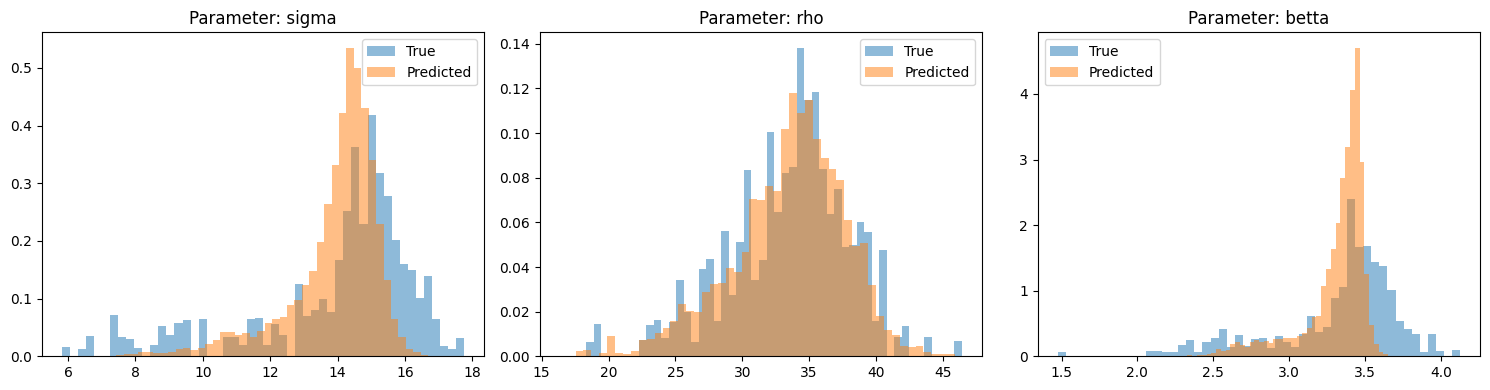

(10240, 3)

In [32]:
plot_parameter_histograms(x_true_1, x_samples_1,run_name,save = True)
x_true.shape

In [28]:
# plot_parameter_histograms(x_true, x_samples)
run_name

'ANN_l63_GMM_dt1_T1_w28_v0'

In [66]:
def plot_parameter_scatter(x_true, x_samples, run_name):
    """
    Plots histograms of true vs predicted parameters for all features.
    
    Args:
        x_true: numpy array of true parameters, shape (N, x_dim)
        x_samples: numpy array of samples, shape (N, n_samples, x_dim) or (n_samples, N, x_dim)
    """
    param_name = ['sigma', 'rho', 'betta']
    # Ensure shape is (N, n_samples, x_dim)
    if x_samples.shape[0] != x_true.shape[0]:
        x_samples = np.transpose(x_samples, (1, 0, 2))

    x_pred_mean = np.mean(x_samples, axis=1)  # mean over samples

    n_features = x_true.shape[1]
    fig, axes = plt.subplots(1, n_features, figsize=(5*n_features, 4))

    if n_features == 1:
        axes = [axes]  # ensure iterable if only one feature

    for i in range(n_features):
        axes[i].scatter(x_true[:, i], x_pred_mean[:, i], alpha=0.5, label='True')
        axes[i].set_title(f'Parameter: {param_name[i]}',fontsize = 14)
        axes[i].plot([x_true[:, i].min(),x_true[:, i].max()],[x_true[:, i].min(),x_true[:, i].max()],color = 'orange')
        axes[i].set_xlabel('True',fontsize = 14)
        # axes[i].legend()
    axes[0].set_ylabel('predicted',fontsize = 14)
    
    plt.tight_layout()
    plt.show()
    fig.savefig(f"./plots/{run_name}-scatter.jpeg",bbox_inches = 'tight',dpi  =100)
    


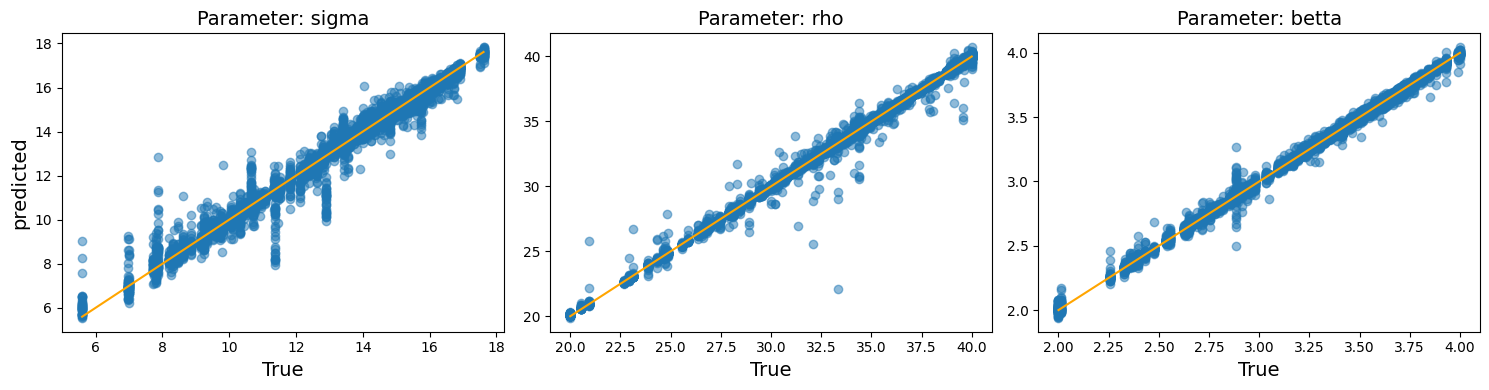

In [151]:
plot_parameter_scatter(x_true, x_samples,run_name)


In [13]:
c_vals.shape,x_true.shape

((10240, 10, 3), (10240, 3))

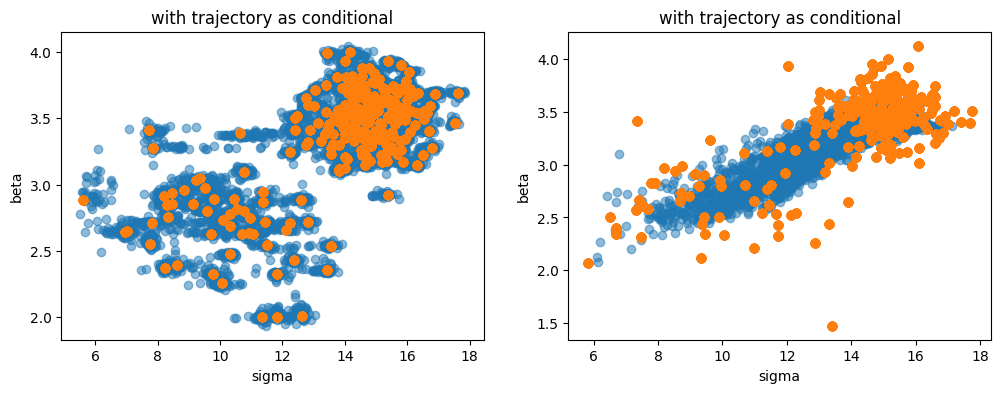

In [49]:
mean_smaple = np.mean(x_samples,1)
fig, axs = plt.subplots(nrows = 1, ncols = 2, figsize=(12,4))
_ = axs[0].scatter(mean_smaple[:,0], mean_smaple[:,2],alpha= 0.5)
_ = axs[0].scatter(x_true[:,0], x_true[:,2])
axs[0].set_title("with trajectory as conditional")

_ = axs[1].scatter(mean_smaple_1[:,0], mean_smaple_1[:,2],alpha= 0.5)
_ = axs[1].scatter(x_true_1[:,0], x_true_1[:,2])
axs[1].set_title("with trajectory as conditional")
axs[1].set_ylabel('beta')
axs[1].set_xlabel('sigma')

axs[0].set_ylabel('beta')
axs[0].set_xlabel('sigma')

fig.savefig("trajectory_vs_instant.jpeg", bbox_inches ="tight",dpi = 100)

In [ ]:
mean_smaple = np.mean(x_samples,1)
plt.
_ = plt.scatter(x_samples[::100,0], x_samples[:,2],alpha= 0.5)
_ = plt.scatter(x_true[:,0], x_true[:,2])
plt.title("with trajectory as conditional")

Text(0.5, 1.0, 'with instance as conditional')

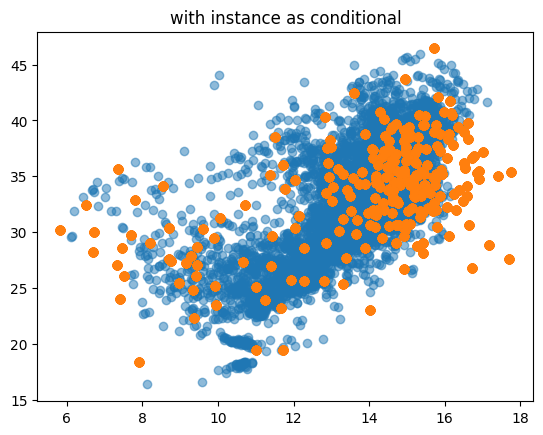

In [50]:
mean_smaple_1 = np.mean(x_samples_1,1)

_ = plt.scatter(mean_smaple_1[:,0], mean_smaple_1[:,1],alpha= 0.5)
_ = plt.scatter(x_true_1[:,0], x_true_1[:,1])
plt.title('with instance as conditional')

np.float32(35.874237)

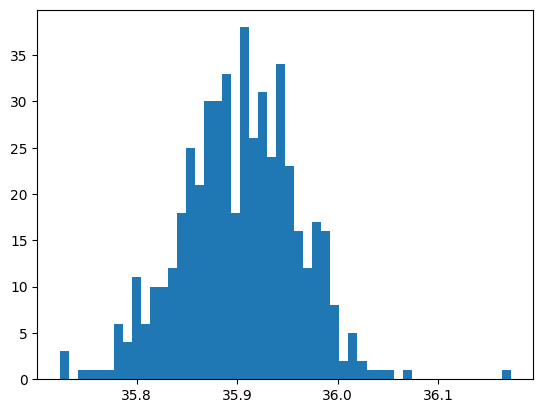

In [19]:
x_samples.shape
_ = plt.hist(x_samples[140,:,1], bins = 50)
x_true[140,1]

array([ 9.956536 , 23.497162 ,  2.7945127], dtype=float32)

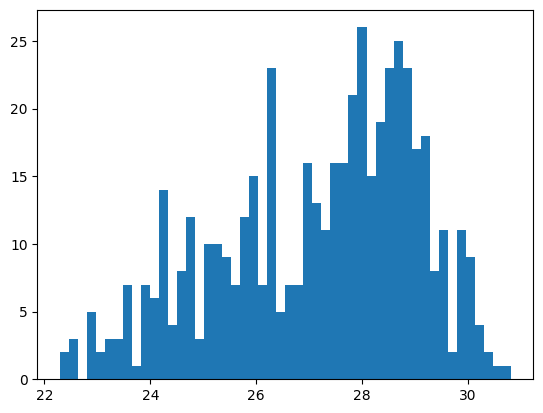

In [51]:
x_samples.shape
_ = plt.hist(x_samples_1[1400,:,1], bins = 50)
x_true_1[1400,:]

# Some summary

The parameter sigma is not well predicted. in fact the model gets the mean right but the distrubution is gaussianized!
Can we fix this problem? 
options to consider: 
change dt as sigma may appear only in fast time scale--> reducing dt from 10 to 5 (sample the trajectory every 5 time step) did not help
change T and dt --> change dt to 2 so we see the trajectory on much faster time steps and also reduce T to 30 (it was 100 before) as we may not neet to obserev the system for that long. 
Reducing dt to 2 imporve the prediction of sigma, but only slightly!
Making the model bigger helped a bit as well

In [18]:
total_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Total trainable parameters: {total_params}")


Total trainable parameters: 157464


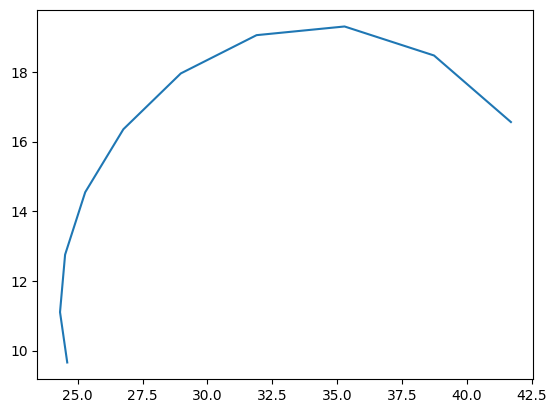

In [12]:
case = 30
plt.plot(trajs[case,:,2],trajs[case,:,1])

In [ ]:
import numpy as np
from scipy.spatial.distance import cdist

x_true_1
# Compute all pairwise distances
distances = cdist(x_true, x_true_1, metric='euclidean')  # Shape: (n1, n2)

# Find minimum distance
min_idx = np.unravel_index(np.argmin(distances), distances.shape)
i, j = min_idx

print(f"Most similar pair: array1[{i}] and array2[{j}]")
print(f"Distance: {distances[i, j]:.4f}")
print(f"Sample 1: {x_true[i]}")
print(f"Sample 2: {x_true_1[j]}")